# 08 · Fishing pressure, stock resilience and recovery

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=08_fish_stocks.ipynb)

**Evidence: a published FAO summary and a separate synthetic biomass model.** Distinguish a stock assessment from a vessel activity map, and explore why growth and fishing mortality jointly shape recovery.

Source for observed summary: [FAO 2025 marine fish-stock assessment](https://www.fao.org/newsroom/detail/fao-releases-the-most-detailed-global-assessment-of-marine-fish-stocks-to-date). These figures describe that assessment, not an automatically updated estimate.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## Two true percentages with different denominators
FAO's 2025 review reports 64.5% of assessed stocks at biologically sustainable levels and 77.2% of landings from biologically sustainable stocks when weighted by production. A stock-count percentage and a production-weighted percentage answer different questions. The assessment covers 2,570 stocks; it should not be mechanically appended to earlier assessment series without checking methodology.

,indicator,sustainable_percent
0,Stock-count share,64.5
1,Production-weighted landings share,77.2


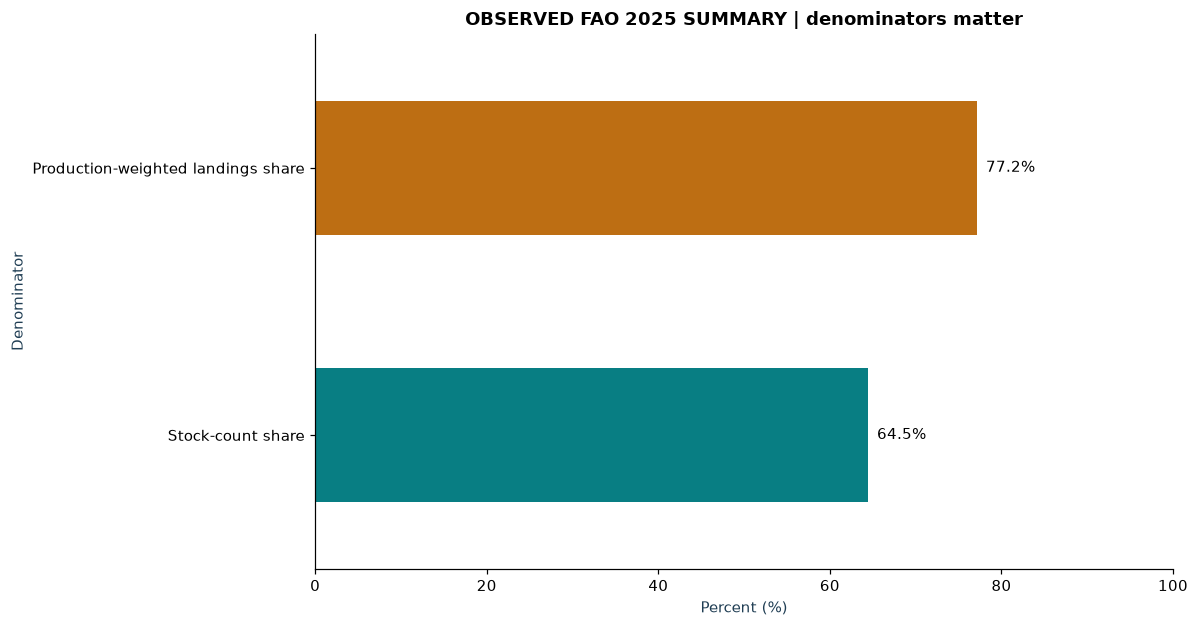

In [2]:
fao=json.loads((lab.DATA/"fao_2025_summary.json").read_text())
summary=pd.DataFrame({"indicator":["Stock-count share","Production-weighted landings share"],"sustainable_percent":[fao["sustainable_stock_count_percent"],fao["sustainable_production_weighted_landings_percent"]]})
display(summary)
ax=summary.plot.barh(x="indicator",y="sustainable_percent",color=["#087e83","#bd6e13"],legend=False)
ax.set(xlim=(0,100),xlabel="Percent (%)",ylabel="Denominator",title="OBSERVED FAO 2025 SUMMARY | denominators matter")
for y,v in enumerate(summary.sustainable_percent):ax.text(v+1,y,f"{v}%",va="center")
plt.tight_layout();plt.show()

## A deliberately simple population model
We use logistic growth with proportional fishing mortality:

`dB/dt = r B (1 − B/K) − F B`.

`B` is biomass, `r` intrinsic growth per year, `K` carrying capacity, and `F` fishing mortality per year. The model uses illustrative units. Apparent fishing hours are not `F`; converting effort to mortality would require catchability and species-specific evidence.

In [3]:
lab.show(lab.stock_slider())

<iframe title="SYNTHETIC STOCK | changing fishing mortality changes the trajectory" srcdoc="<html>
<head><meta charset="utf-8" /></head>
<body>
 <div> <script type="text/javascript">window.PlotlyConfig = {MathJaxConfig: 'local'};</script>
 <script charset="utf-8" src="https://cdn.plot.ly/plotly-3.3.0.min.js" integrity="sha256-bO3dS6yCpk9aK4gUpNELtCiDeSYvGYnK7jFI58NQnHI=" crossorigin="anonymous"></script> <div id="70075f9f-23de-4666-a548-759feb75c74c" class="plotly-graph-div" style="height:600px; width:100%;"></div> <script type="text/javascript"> window.PLOTLYENV=window.PLOTLYENV || {}; if (document.getElementById("70075f9f-23de-4666-a548-759feb75c74c")) { Plotly.newPlot( "70075f9f-23de-4666-a548-759feb75c74c", [{"line":{"color":"#27c7b8","width":3},"name":"F = 0.1","visible":false,"x":{"dtype":"f8","bdata":"AAAAAAAAAACamZmZmZmpP5qZmZmZmbk\u002fNDMzMzMzwz+amZmZmZnJPwAAAAAAANA\u002fNDMzMzMz0z9nZmZmZmbWP5qZmZmZmdk\u002fzczMzMzM3D8AAAAAAADgP5qZmZmZmeE\u002fNDMzMzMz4z\u002fNzMzMzMzkP2dmZmZmZuY\u002fAAAAAAAA6D+amZmZmZnpPzQzMzMzM+s\u002fzczMzMzM7D9nZmZmZmbuPwAAAAAAAPA\u002fzczMzMzM8D+amZmZmZnxP2dmZmZmZvI\u002fNDMzMzMz8z8AAAAAAAD0P83MzMzMzPQ\u002fmpmZmZmZ9T9nZmZmZmb2PzQzMzMzM\u002fc\u002fAAAAAAAA+D\u002fNzMzMzMz4P5qZmZmZmfk\u002fZ2ZmZmZm+j80MzMzMzP7PwAAAAAAAPw\u002fzczMzMzM\u002fD+amZmZmZn9P2dmZmZmZv4\u002fNDMzMzMz\u002fz8AAAAAAAAAQGdmZmZmZgBAzczMzMzMAEAzMzMzMzMBQJqZmZmZmQFAAAAAAAAAAkBnZmZmZmYCQM3MzMzMzAJANDMzMzMzA0CamZmZmZkDQAAAAAAAAARAZ2ZmZmZmBEDNzMzMzMwEQDQzMzMzMwVAmpmZmZmZBUAAAAAAAAAGQGdmZmZmZgZAzczMzMzMBkA0MzMzMzMHQJqZmZmZmQdAAAAAAAAACEBnZmZmZmYIQM3MzMzMzAhANDMzMzMzCUCamZmZmZkJQAAAAAAAAApAZ2ZmZmZmCkDNzMzMzMwKQDQzMzMzMwtAmpmZmZmZC0AAAAAAAAAMQGdmZmZmZgxAzczMzMzMDEA0MzMzMzMNQJqZmZmZmQ1AAAAAAAAADkBnZmZmZmYOQM3MzMzMzA5ANDMzMzMzD0CamZmZmZkPQAAAAAAAABBAMzMzMzMzEEBnZmZmZmYQQJqZmZmZmRBAzczMzMzMEEAAAAAAAAARQDMzMzMzMxFAZ2ZmZmZmEUCamZmZmZkRQM3MzMzMzBFAAAAAAAAAEkAzMzMzMzMSQGdmZmZmZhJAmpmZmZmZEkDNzMzMzMwSQAAAAAAAABNANDMzMzMzE0BnZmZmZmYTQJqZmZmZmRNAzczMzMzME0AAAAAAAAAUQDQzMzMzMxRAZ2ZmZmZmFECamZmZmZkUQM3MzMzMzBRAAAAAAAAAFUA0MzMzMzMVQGdmZmZmZhVAmpmZmZmZFUDNzMzMzMwVQAAAAAAAABZANDMzMzMzFkBnZmZmZmYWQJqZmZmZmRZAzczMzMzMFkAAAAAAAAAXQDQzMzMzMxdAZ2ZmZmZmF0CamZmZmZkXQM3MzMzMzBdAAAAAAAAAGEA0MzMzMzMYQGdmZmZmZhhAmpmZmZmZGEDNzMzMzMwYQAAAAAAAABlANDMzMzMzGUBnZmZmZmYZQJqZmZmZmRlAzczMzMzMGUAAAAAAAAAaQDQzMzMzMxpAZ2ZmZmZmGkCamZmZmZkaQM3MzMzMzBpAAAAAAAAAG0A0MzMzMzMbQGdmZmZmZhtAmpmZmZmZG0DNzMzMzMwbQAAAAAAAABxANDMzMzMzHEBnZmZmZmYcQJqZmZmZmRxAzczMzMzMHEAAAAAAAAAdQDQzMzMzMx1AZ2ZmZmZmHUCamZmZmZkdQM3MzMzMzB1AAAAAAAAAHkA0MzMzMzMeQGdmZmZmZh5AmpmZmZmZHkDNzMzMzMweQAAAAAAAAB9ANDMzMzMzH0BnZmZmZmYfQJqZmZmZmR9AzczMzMzMH0AAAAAAAAAgQJqZmZmZGSBAMzMzMzMzIEDNzMzMzEwgQGdmZmZmZiBAAAAAAACAIECamZmZmZkgQDMzMzMzsyBAzczMzMzMIEBnZmZmZuYgQAAAAAAAACFAmpmZmZkZIUAzMzMzMzMhQM3MzMzMTCFAZ2ZmZmZmIUAAAAAAAIAhQJqZmZmZmSFAMzMzMzOzIUDNzMzMzMwhQGdmZmZm5iFAAAAAAAAAIkCamZmZmRkiQDMzMzMzMyJAzczMzMxMIkBnZmZmZmYiQAAAAAAAgCJAmpmZmZmZIkAzMzMzM7MiQM3MzMzMzCJAZ2ZmZmbmIkAAAAAAAAAjQJqZmZmZGSNANDMzMzMzI0DNzMzMzEwjQGdmZmZmZiNAAAAAAACAI0CamZmZmZkjQDQzMzMzsyNAzczMzMzMI0BnZmZmZuYjQAAAAAAAACRAmpmZmZkZJEA0MzMzMzMkQM3MzMzMTCRAZ2ZmZmZmJEAAAAAAAIAkQJqZmZmZmSRANDMzMzOzJEDNzMzMzMwkQGdmZmZm5iRAAAAAAAAAJUCamZmZmRklQDQzMzMzMyVAzczMzMxMJUBnZmZmZmYlQAAAAAAAgCVAmpmZmZmZJUA0MzMzM7MlQM3MzMzMzCVAZ2ZmZmbmJUAAAAAAAAAmQJqZmZmZGSZANDMzMzMzJkDNzMzMzEwmQGdmZmZmZiZAAAAAAACAJkCamZmZmZkmQDQzMzMzsyZAzczMzMzMJkBnZmZmZuYmQAAAAAAAACdAmpmZmZkZJ0A0MzMzMzMnQM3MzMzMTCdAZ2ZmZmZmJ0AAAAAAAIAnQJqZmZmZmSdANDMzMzOzJ0DNzMzMzMwnQGdmZmZm5idAAAAAAAAAKECamZmZmRkoQDQzMzMzMyhAzczMzMxMKEBnZmZmZmYoQAAAAAAAgChAmpmZmZmZKEA0MzMzM7MoQM3MzMzMzChAZ2ZmZmbmKEAAAAAAAAApQJqZmZmZGSlANDMzMzMzKUDNzMzMzEwpQGdmZmZmZilAAAAAAACAKUCamZmZmZkpQDQzMzMzsylAzczMzMzMKUBnZmZmZuYpQAAAAAAAACpAmpmZmZkZKkA0MzMzMzMqQM3MzMzMTCpAZ2ZmZmZmKkAAAAAAAIAqQJqZmZmZmSpANDMzMzOzKkDNzMzMzMwqQGdmZmZm5ipAAAAAAAAAK0CamZmZmRkrQDQzMzMzMytAzczMzMxMK0BnZmZmZmYrQAAAAAAAgCtAmpmZmZmZK0A0MzMzM7MrQM3MzMzMzCtAZ2ZmZmbmK0AAAAAAAAAsQJqZmZmZGSxANDMzMzMzLEDNzMzMzEwsQGdmZmZmZixAAAAAAACALECamZmZmZksQDQzMzMzsyxAzczMzMzMLEBnZmZmZu

## More unobserved effort is an assumption to test
If total mortality were proportional to total effort, then `F_total = F_observed / (1 − hidden_share)`. That proportionality is a hypothetical scenario, not an inference from SAR unmatched fractions. The unmatched fractions in this book must not be substituted directly for `hidden_share`. Catchability, gear, species and behavior can differ.

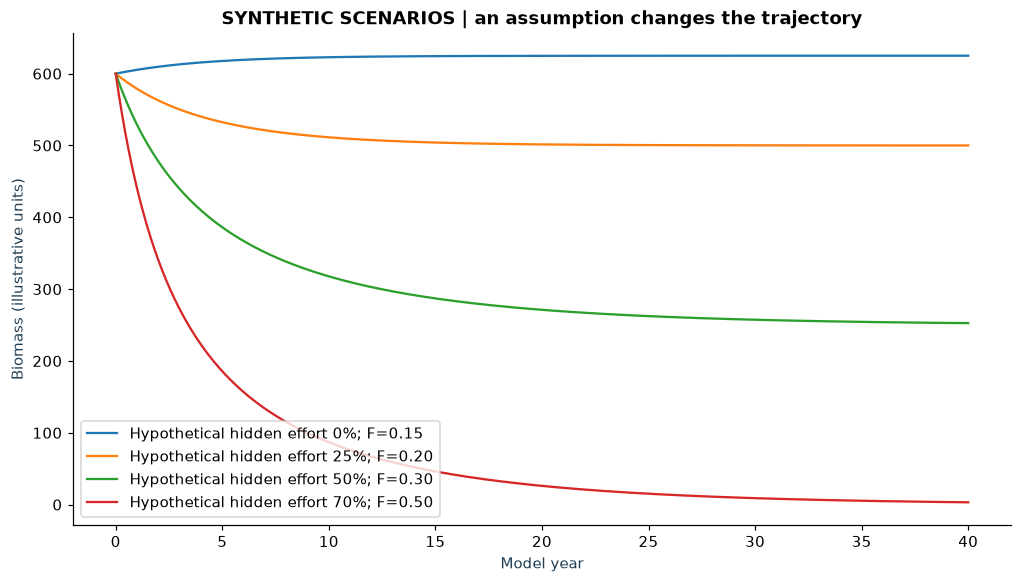

In [4]:
F_OBSERVED=.15
fig,ax=plt.subplots()
for share in [0,.25,.50,.70]:
    F_total=F_OBSERVED/(1-share)
    t,b=lab.stock_model(fishing_mortality=F_total)
    ax.plot(t,b,label=f"Hypothetical hidden effort {share:.0%}; F={F_total:.2f}")
ax.set(xlabel="Model year",ylabel="Biomass (illustrative units)",title="SYNTHETIC SCENARIOS | an assumption changes the trajectory")
ax.legend();plt.show()

## Recovery has conditions
In this model, a positive equilibrium exists when `F < r` and equals `K(1 − F/r)`. The model's maximum sustainable yield occurs at `B = K/2` and `F = r/2`. Those formulas are not management advice for a real stock. Real systems need uncertainty, stock structure, recruitment, climate, species interactions and socioeconomic evidence.

**Try it:** change `r` and initial biomass while holding `F` fixed. Then design a recovery scenario with a timed mortality reduction. Explain why improved vessel visibility alone does not guarantee recovery, nutrition, or fair access.